# Surya + MLP Prototype

## 0. Prerrequisites and imports

In [25]:
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
from notebook_utils.viz import get_channel_display
import torch.nn.functional as F
import torch

Upload dataset.

In [26]:
from notebook_utils.dataset import SuryaBatch

batch = SuryaBatch.load(index=2)              # acá eliges cuál de las 8 muestras
print(f"{len(batch.dataset)} sample(s) en el dataset")

8 sample(s) en el dataset


Upload model spectral-attention embedding.

In [27]:
from notebook_utils.model import SuryaModel

device = "cuda" if torch.cuda.is_available() else "cpu"
surya = SuryaModel.load(config=batch.config,
                        device=device,)
tokens = surya.embed_batch(batch.batch_data)
tokens.shape

torch.Size([1, 65536, 1280])

Charge the model.

## 1. Crop tokens

Let's define a function for cropping the tokens of the prcessed observation.

In [28]:
def crop_tokens(tokens, bbox_px, patch_size=16, grid_size=256):
    """bbox_px: (x_min, y_min, x_max, y_max) en pixeles sobre la imagen 4096x4096."""
    x_min, y_min, x_max, y_max = bbox_px
    tx_min, ty_min = x_min // patch_size, y_min // patch_size
    tx_max, ty_max = -(-x_max // patch_size), -(-y_max // patch_size)  # techo (ceil)
    grid = tokens.reshape(tokens.shape[0], grid_size, grid_size, tokens.shape[-1])
    cropped = grid[:, ty_min:ty_max, tx_min:tx_max, :]
    return cropped  # (B, h_tokens, w_tokens, D)


In [29]:
def plot_token_crop(ts, config, full_tokens, channel, bbox_px, patch_size=16, grid_size=256) -> None:
    """
    Plots both input observations (t=-60 min, t=0 min) and the token attention map, full and cropped to bbox_px.

    Args:
        ts (torch.Tensor): A single sample's tensor, shape (C, T, H, W) -- e.g. batch_data["ts"][0].
        config (dict): Parsed config.yaml, for channel lookup.
        full_tokens (torch.Tensor): The full token embeddings, shape (B, L, D) with L = grid_size**2.
        channel (str): A channel name or friendly alias -- see notebook_utils.viz.resolve_channel_name
            (e.g. "304", "magnetogram"). Colormap and vmin/vmax are resolved automatically from this.
        bbox_px (tuple): A tuple (x_min, y_min, x_max, y_max) defining the bounding box in pixel coordinates.
        patch_size (int): The size of each patch in pixels. Default is 16.
        grid_size (int): The size of the grid (number of patches along one dimension). Default is 256.
    """
    obs_early, cmap, vmin, vmax = get_channel_display(ts, config, channel, timestep=0)   # t = -60 min
    obs_recent, _, _, _ = get_channel_display(ts, config, channel, timestep=-1)          # t = 0 min -- mismo cmap/vmin/vmax
    norms = full_tokens[0].norm(dim=-1).reshape(grid_size, grid_size).cpu()

    x_min, y_min, x_max, y_max = bbox_px
    tx_min, ty_min = x_min // patch_size, y_min // patch_size
    tx_max, ty_max = -(-x_max // patch_size), -(-y_max // patch_size)

    fig, ax = plt.subplots(2, 3, figsize=(15, 10))

    ax[0, 0].imshow(obs_early.cpu(), cmap=cmap, vmin=vmin, vmax=vmax)
    ax[0, 0].set_title("Observación t=-60 min")
    ax[0, 0].add_patch(plt.Rectangle((x_min, y_min), x_max - x_min, y_max - y_min, ls="--", lw=2, ec="r", fc="none"))

    ax[0, 1].imshow(obs_recent.cpu(), cmap=cmap, vmin=vmin, vmax=vmax)
    ax[0, 1].set_title("Observación t=0 min")
    ax[0, 1].add_patch(plt.Rectangle((x_min, y_min), x_max - x_min, y_max - y_min, ls="--", lw=2, ec="r", fc="none"))

    im = ax[0, 2].imshow(norms, cmap="turbo")
    ax[0, 2].set_title("Norma L2 por token — grilla 256x256")
    divider = make_axes_locatable(ax[0, 2])
    cax = divider.append_axes("right", size="5%", pad=0.05)
    fig.colorbar(im, cax=cax, orientation="vertical")
    ax[0, 2].set_xlabel("Coordenada X")
    ax[0, 2].set_ylabel("Coordenada Y")
    ax[0, 2].add_patch(plt.Rectangle((tx_min, ty_min), tx_max - tx_min, ty_max - ty_min, ls="--", lw=2, ec="r", fc="none"))

    ax[1, 0].imshow(obs_early[y_min:y_max, x_min:x_max].cpu(), cmap=cmap, vmin=vmin, vmax=vmax)
    ax[1, 0].set_title("Recorte t=-60 min")

    ax[1, 1].imshow(obs_recent[y_min:y_max, x_min:x_max].cpu(), cmap=cmap, vmin=vmin, vmax=vmax)
    ax[1, 1].set_title("Recorte t=0 min")

    ax[1, 2].imshow(norms[ty_min:ty_max, tx_min:tx_max], cmap="turbo")
    ax[1, 2].set_title("Recorte mapa de atención")

    fig.savefig("forward_pass_embedding_norm.png", dpi=100, bbox_inches="tight")


Let's define the bbox for an active region on the uploaded sample to check how the tokens would be cropped.

In [30]:
bbox_px = (1600, 1600, 2304, 2304)  # el mismo bbox que le pasarías a crop_tokens
patch_size = 16

x_min, y_min, x_max, y_max = bbox_px
tx_min, ty_min = x_min // patch_size, y_min // patch_size
tx_max, ty_max = -(-x_max // patch_size), -(-y_max // patch_size)  # misma division techo que crop_tokens

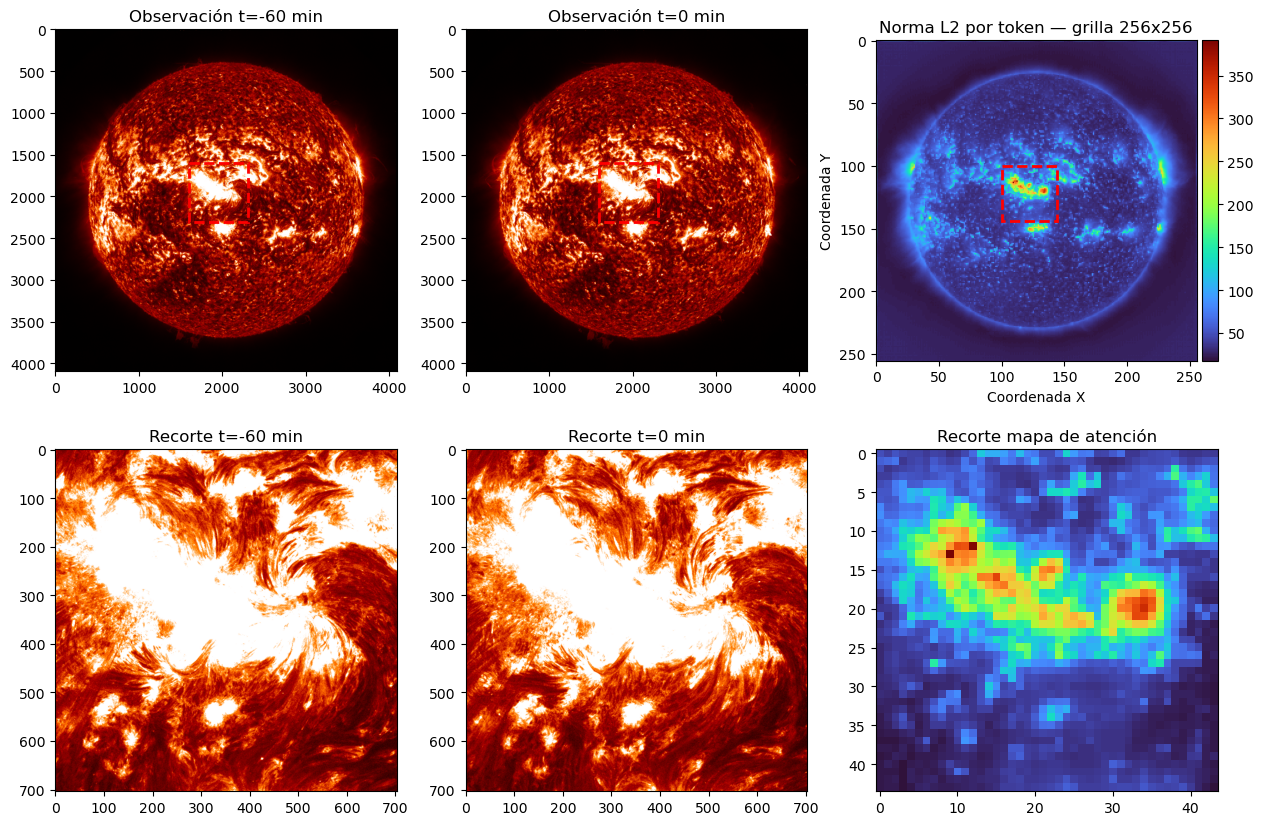

In [31]:
tokens = surya.embed_batch(batch.batch_data)  # tokens de esa misma muestra

plot_token_crop(ts = batch.batch_data["ts"][0], 
                config = batch.config, 
                full_tokens = tokens, 
                channel = "304", 
                bbox_px = bbox_px,
                patch_size = 16,
                grid_size = 256)


In [32]:
cropped_tokens = crop_tokens(tokens, bbox_px, patch_size=16, grid_size=256)
norms_cropped = cropped_tokens[0].norm(dim=-1).cpu()

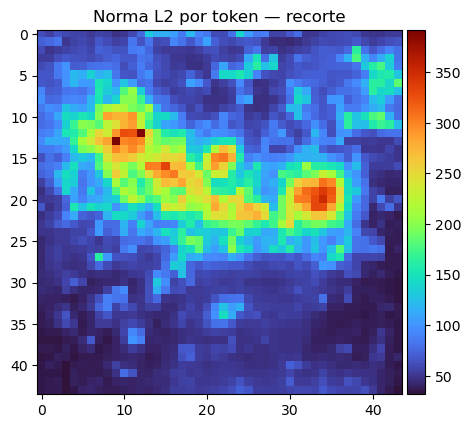

In [33]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
im = ax.imshow(norms_cropped, cmap="turbo")
ax.set_title("Norma L2 por token — recorte")
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="5%", pad=0.05)
fig.colorbar(im, cax=cax, orientation="vertical")
plt.show()

## 2. Pooling

To keep the cost of attending to visual tokens manageable for the LLM — not because 1024 tokens would literally overflow its context window, but because self-attention cost grows worse than linearly with sequence length — we apply 2D adaptive pooling, reducing the cropped region to a 16×16 (256-token) grid. This trades some spatial resolution for a fixed, LLaVA-1.5-scale token budget, while still keeping enough structure to describe the region.

In [34]:
def pool_tokens(cropped, out_size=16):
    """
    Pooling 2D on the tokens. The input is expected to be of shape (B, h, w, D) and the output will be of shape (B, out_size*out_size, D).
    Args:
        cropped (torch.Tensor): The cropped tokens of shape (B, h, w, D).
        out_size (int): The desired output size for the pooled tokens. Default is 16.
    Returns:
        torch.Tensor: The pooled tokens of shape (B, out_size*out_size, D).
    """
    B, h, w, D = cropped.shape
    x = cropped.permute(0, 3, 1, 2)  # (B, D, h, w) -- pooling 2D espera canales primero
    x = F.adaptive_avg_pool2d(x, output_size=(out_size, out_size))
    x = x.permute(0, 2, 3, 1).reshape(B, out_size * out_size, D)
    return x  # (B, out_size*out_size, D)


In [ ]:
pooled = pool_tokens(cropped=cropped_tokens)
norms_pooled = pooled[0].norm(dim=-1).cpu().reshape(16, 16)

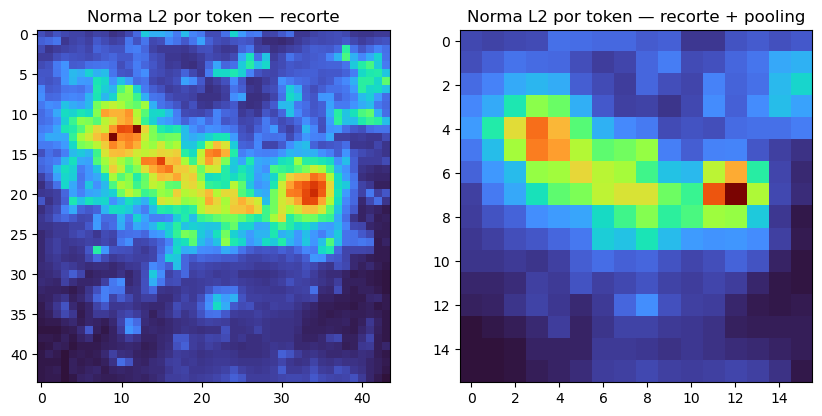

In [36]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(norms_cropped, cmap="turbo")
ax[0].set_title("Norma L2 por token — recorte")
ax[1].imshow(norms_pooled, cmap="turbo")
ax[1].set_title("Norma L2 por token — recorte + pooling")
plt.show()


## 3. Proyector tipo LLaVA-1.5

In [37]:
from torch import nn

class Projector(nn.Module):
    def __init__(self, in_dim=1280, out_dim=4096):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, out_dim),
            nn.GELU(),
            nn.Linear(out_dim, out_dim),
        )
    def forward(self, x):
        return self.net(x)


## 4. Freezing Surya

In [42]:
for p in surya.model.parameters():  # surya.model es el HelioSpectFormer real
    p.requires_grad = False

projector = Projector().to(device)
visual_tokens = projector(pooled)  # (1, 256, 4096) -- esto recibiria el LLM

loss = visual_tokens.sum()  # loss de juguete, solo para verificar el flujo de gradientes
loss.backward()
proj_grad_ok = all(p.grad is not None for p in projector.parameters())
surya_has_grad = any(p.grad is not None for p in surya.model.parameters())

print("visual_tokens shape:", visual_tokens.shape)
print("Projector N trainable params:", sum(p.numel() for p in projector.parameters() if p.requires_grad) / 1000000, "M")
print("Surya N parameters with requires_grad=True:", sum(p.numel() for p in surya.model.parameters() if p.requires_grad))
print("Projector parameters with requires_grad=True:", any(p.requires_grad for p in projector.parameters()))
print("Surya has gradients:", any(p.grad is not None for p in surya.model.parameters()))

visual_tokens shape: torch.Size([1, 256, 4096])
Projector N trainable params: 22.028288 M
Surya N parameters with requires_grad=True: 0
Projector parameters with requires_grad=True: True
Surya has gradients: False
